In [1]:
import pandas as pd

df = pd.read_csv("CPI.csv")
print(df.head())  # pokaż pierwsze wiersze

  observation_date  CPIAUCSL_PC1
0       1948-01-01      10.24209
1       1948-02-01       9.48196
2       1948-03-01       6.81818
3       1948-04-01       8.27273
4       1948-05-01       9.38497


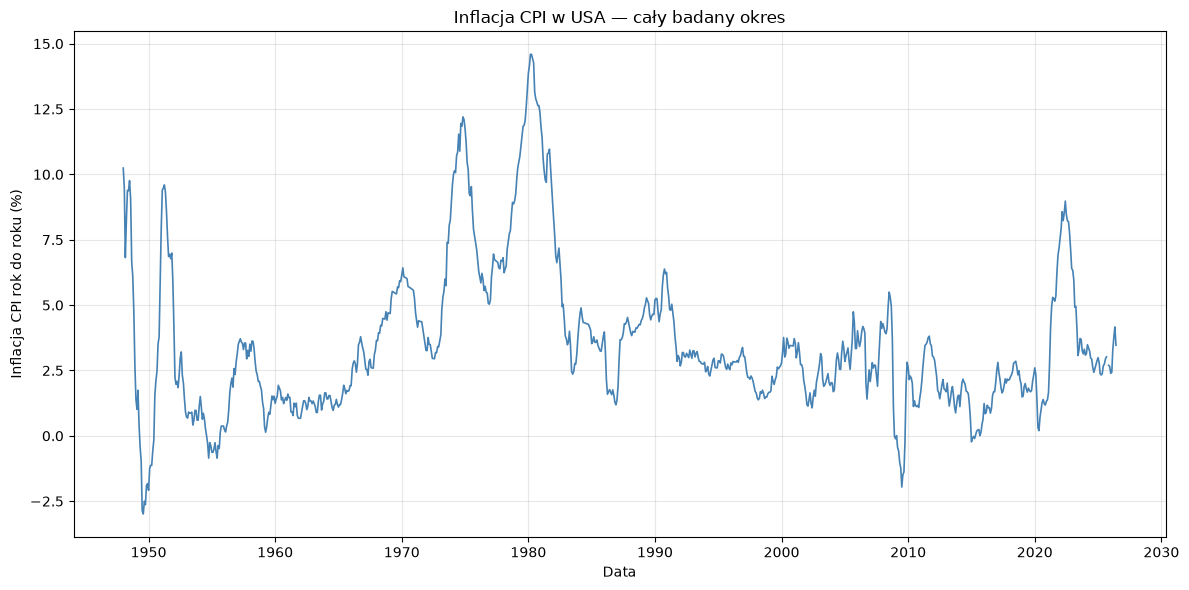

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.sort_values("observation_date")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df["observation_date"], df["CPIAUCSL_PC1"], color="steelblue", linewidth=1.2)
ax.set_title("Inflacja CPI w USA — cały badany okres")
ax.set_xlabel("Data")
ax.set_ylabel("Inflacja CPI rok do roku (%)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [3]:
stats = df["CPIAUCSL_PC1"].agg(["min", "max", "std", "median"])
stats.index = ["Minimum (%)", "Maksimum (%)", "Odchylenie standardowe (p.p.)", "Mediana (%)"]
print(stats.round(2))

Minimum (%)                      -2.99
Maksimum (%)                     14.59
Odchylenie standardowe (p.p.)     2.86
Mediana (%)                       2.86
Name: CPIAUCSL_PC1, dtype: float64


In [2]:
import pandas as pd

# CPIAUCSL to poziom indeksu CPI (dane miesięczne, wyrównane sezonowo) z FRED.
cpi = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL")
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
cpi["CPIAUCSL"] = pd.to_numeric(cpi["CPIAUCSL"], errors="coerce")
cpi = cpi.dropna(subset=["CPIAUCSL"]).sort_values("observation_date")

# Średnia wartość indeksu w każdym kwartale i zmiana względem poprzedniego kwartału.
cpi_kwartalnie = (
    cpi.set_index("observation_date")["CPIAUCSL"]
    .resample("QS")
    .mean()
    .dropna()
)
inflacja_kwartalna = cpi_kwartalnie.pct_change(fill_method=None).mul(100)
inflacja_kwartalna.name = "Inflacja kwartał do kwartału (%)"

print(inflacja_kwartalna.dropna().round(2).tail(10))

observation_date
2024-04-01    0.67
2024-07-01    0.33
2024-10-01    0.79
2025-01-01    0.91
2025-04-01    0.41
2025-07-01    0.76
2025-10-01    0.72
2026-01-01    0.79
2026-04-01    1.48
2026-07-01    0.43
Freq: QS-JAN, Name: Inflacja kwartał do kwartału (%), dtype: float64


In [2]:
import pandas as pd

df = pd.read_csv("CPI.csv")
dekady = pd.to_datetime(df["observation_date"]).dt.year // 10 * 10
dekady.name = "Dekada"

srednia_inflacja_dekady = (
    df.groupby(dekady)["CPIAUCSL_PC1"]
    .agg(srednia_inflacji="mean", liczba_miesiecy="count")
)
srednia_inflacja_dekady.index = srednia_inflacja_dekady.index.map(
    lambda rok: f"{rok}-{rok + 9}"
)
srednia_inflacja_dekady = srednia_inflacja_dekady.rename(
    columns={
        "srednia_inflacji": "Średnia inflacja (%)",
        "liczba_miesiecy": "Liczba miesięcy",
    }
)

print(srednia_inflacja_dekady.round(2))

           Średnia inflacja (%)  Liczba miesięcy
Dekada                                          
1940-1949                  3.38               24
1950-1959                  2.07              120
1960-1969                  2.33              120
1970-1979                  7.09              120
1980-1989                  5.56              120
1990-1999                  3.01              120
2000-2009                  2.57              120
2010-2019                  1.77              120
2020-2029                  3.92               77
